In [4]:
import pandas as pd

In [5]:
data= pd.read_csv("/Users/sayad.alakbarov/Desktop/usa_00001.csv")

In [6]:
crosswalk = pd.read_csv("/Users/sayad.alakbarov/Desktop/PPHA_30545_MP01-Crosswalk.csv")

In [ ]:
#question-3a
data_cleaned = data.merge(crosswalk, left_on='EDUCD', right_on='educd', how='left')

In [ ]:


data_cleaned[['EDUCD', 'educdc']].head()

,EDUCD,educdc
0,71,14.0
1,63,12.0
2,101,16.0
3,63,12.0
4,81,14.0


In [ ]:
#question-3b,c,d
import numpy as np


data_cleaned['ln_incwage'] = np.log(data_cleaned['INCWAGE'].replace(0, np.nan))  # Natural log of INCWAGE


data_cleaned['female'] = (data_cleaned['SEX'] == 2).astype(int)  # Assuming 'SEX' column: 2 = Female


data_cleaned['white'] = (data_cleaned['RACE'] == 1).astype(int)  # Assuming 'RACE' column: 1 = White


data_cleaned['black'] = (data_cleaned['RACE'] == 2).astype(int)  # Assuming 'RACE' column: 2 = Black

data_cleaned['hispanic'] = (data_cleaned['HISPAN'] == 1).astype(int)  # Assuming 'HISPAN' column: 1 = Hispanic origin


data_cleaned['married'] = (data_cleaned['MARST'] == 1).astype(int)  # Assuming 'MARST' column: 1 = Married


data_cleaned['vet'] = (data_cleaned['VETSTAT'] == 1).astype(int)  # Assuming 'VETSTAT' column: 1 = Veteran


data_cleaned['hsdip'] = ((data_cleaned['EDUCD'] == 71) | (data_cleaned['EDUCD'] == 63)) & (data_cleaned['EDUCD'] != 81)


data_cleaned['coldip'] = data_cleaned['EDUCD'].apply(lambda x: 1 if x >= 101 else 0)


data_cleaned['hsdip_educdc'] = data_cleaned['hsdip'] * data_cleaned['educdc']


data_cleaned['coldip_educdc'] = data_cleaned['coldip'] * data_cleaned['educdc']


data_cleaned['age_squared'] = data_cleaned['AGE'] ** 2



variables = [
    'YEAR', 'INCWAGE', 'ln_incwage', 'educdc', 'female', 'AGE', 'age_squared', 
    'white', 'black', 'hispanic', 'married', 'NCHILD', 'vet', 'hsdip', 'coldip', 
    'hsdip_educdc', 'coldip_educdc'
]

# Compute descriptive statistics
summary_stats = data_cleaned[variables].describe()

# Display the summary statistics
summary_stats

,YEAR,INCWAGE,ln_incwage,educdc,female,AGE,age_squared,white,black,hispanic,married,NCHILD,vet,coldip,hsdip_educdc,coldip_educdc
count,9338.0,9338.000000,8835.000000,9338.000000,9338.000000,9338.000000,9338.000000,9338.000000,9338.000000,9338.000000,9338.000000,9338.000000,9338.000000,9338.000000,9338.000000,9338.000000
mean,2023.0,64926.139430,10.640227,14.231099,0.481152,42.854894,2041.017884,0.659991,0.080960,0.091883,0.532448,0.760227,0.952559,0.404048,4.179910,6.860141
std,0.0,79311.725631,1.140417,3.058343,0.499671,14.300274,1244.238034,0.473737,0.272788,0.288876,0.498973,1.107490,0.212591,0.490733,6.023567,8.383310
min,2023.0,0.000000,3.401197,0.000000,0.000000,16.000000,256.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2023.0,22000.000000,10.165852,12.000000,0.000000,31.000000,961.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
50%,2023.0,46800.000000,10.819778,14.000000,0.000000,43.000000,1849.000000,1.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000
75%,2023.0,80000.000000,11.350407,16.000000,1.000000,55.000000,3025.000000,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,12.000000,16.000000
max,2023.0,770000.000000,13.554146,22.000000,1.000000,70.000000,4900.000000,1.000000,1.000000,1.000000,1.000000,9.000000,1.000000,1.000000,14.000000,22.000000


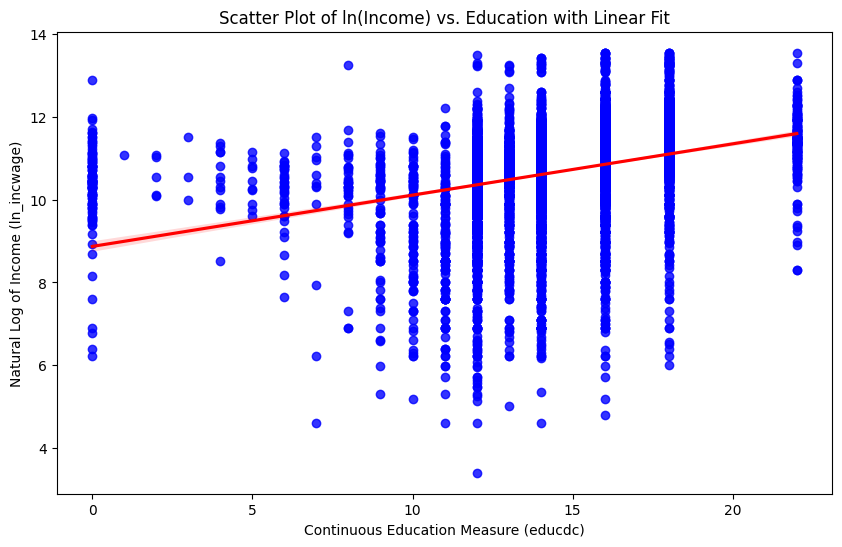

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


plt.figure(figsize=(10, 6))
sns.regplot(x='educdc', y='ln_incwage', data=data_cleaned, scatter_kws={'color': 'blue'}, line_kws={'color': 'red'})


plt.xlabel('Continuous Education Measure (educdc)')
plt.ylabel('Natural Log of Income (ln_incwage)')
plt.title('Scatter Plot of ln(Income) vs. Education with Linear Fit')

# Show the plot
plt.show()

In [ ]:

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Create a new dataframe with the independent variables (excluding the dependent variable 'ln_incwage')
X_vif = data_cleaned[['educdc', 'female', 'AGE', 'white', 'black', 'hispanic', 'married', 'NCHILD', 'vet']]

# Add a constant to the independent variables (for the intercept)
X_vif = add_constant(X_vif)

# Calculate VIF for each feature
vif_data = pd.DataFrame()
vif_data["Variable"] = X_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]

# Display VIF results
print(vif_data)

   Variable        VIF
0     const  56.207404
1    educdc   1.081850
2    female   1.031698
3       AGE   1.166327
4     white   1.467319
5     black   1.312490
6  hispanic   1.249739
7   married   1.363708
8    NCHILD   1.156671
9       vet   1.024983


In [23]:
# Check for any extreme or problematic values
data_cleaned.describe()

,YEAR,SAMPLE,SERIAL,CBSERIAL,HHWT,CLUSTER,STRATA,GQ,PERNUM,PERWT,...,white,black,hispanic,married,female,vet,hsdip_educdc,coldip_educdc,age_squared,ln_incwage
count,9338.0,9338.0,9.338000e+03,9.338000e+03,9338.000000,9.338000e+03,9.338000e+03,9338.000000,9338.000000,9338.000000,...,9338.000000,9338.000000,9338.000000,9338.000000,9338.000000,9338.000000,9338.000000,9338.000000,9338.000000,8835.000000
mean,2023.0,202301.0,7.577259e+05,2.023001e+12,17083.540158,2.023008e+12,4.817177e+05,1.055901,1.717927,17241.029557,...,0.659991,0.080960,0.091883,0.532448,0.481152,0.952559,4.179910,6.860141,2041.017884,10.640227
std,0.0,0.0,4.410536e+05,1.297377e+06,15329.965443,4.410536e+06,8.098383e+05,0.402522,0.997857,15706.638206,...,0.473737,0.272788,0.288876,0.498973,0.499671,0.212591,6.023567,8.383310,1244.238034,1.140417
min,2023.0,202301.0,1.471000e+03,2.023000e+12,486.000000,2.023000e+12,1.000100e+04,1.000000,1.000000,162.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,256.000000,3.401197
25%,2023.0,202301.0,3.690895e+05,2.023000e+12,8262.000000,2.023004e+12,9.062500e+04,1.000000,1.000000,8424.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,961.000000,10.165852
50%,2023.0,202301.0,7.516120e+05,2.023001e+12,12474.000000,2.023008e+12,2.305480e+05,1.000000,1.000000,12474.000000,...,1.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1849.000000,10.819778
75%,2023.0,202301.0,1.142275e+06,2.023001e+12,20088.000000,2.023011e+12,4.706390e+05,1.000000,2.000000,20412.000000,...,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000,12.000000,16.000000,3025.000000,11.350407
max,2023.0,202301.0,1.518925e+06,2.023010e+12,208170.000000,2.023015e+12,8.100351e+06,5.000000,12.000000,252396.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,14.000000,22.000000,4900.000000,13.554146


In [ ]:

data_cleaned_no_nan = data_cleaned.dropna(subset=['ln_incwage'])

# Define the independent variables and the dependent variable again
X_cleaned = data_cleaned_no_nan[['educdc', 'female', 'AGE', 'white', 'black', 'hispanic', 'married', 'NCHILD', 'vet']]
y_cleaned = data_cleaned_no_nan['ln_incwage']

# Scale the data again
X_scaled_cleaned = scaler.fit_transform(X_cleaned)
X_scaled_cleaned = sm.add_constant(X_scaled_cleaned)

# Fit the robust model
robust_model_cleaned = sm.RLM(y_cleaned, X_scaled_cleaned).fit()

# Display the robust regression results
robust_model_cleaned.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                    Robust linear Model Regression Results                    
==============================================================================
Dep. Variable:             ln_incwage   No. Observations:                 8835
Model:                            RLM   Df Residuals:                     8825
Method:                          IRLS   Df Model:                            9
Norm:                          HuberT                                         
Scale Est.:                       mad                                         
Cov Type:                          H1                                         
Date:                Thu, 23 Oct 2025                                         
Time:                        16:28:05                                         
No. Iterations:                    31                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         10.7471      0.008   1269.126      0.000      10.731      10.764
x1             0.3547      0.009     40.268      0.000       0.337       0.372
x2            -0.1881      0.009    -21.875      0.000      -0.205      -0.171
x3             0.2149      0.009     23.493      0.000       0.197       0.233
x4            -0.0117      0.010     -1.144      0.253      -0.032       0.008
x5            -0.0360      0.010     -3.700      0.000      -0.055      -0.017
x6             0.0005      0.009      0.052      0.958      -0.018       0.019
x7             0.1302      0.010     13.139      0.000       0.111       0.150
x8             0.0766      0.009      8.411      0.000       0.059       0.095
x9             0.0158      0.009      1.845      0.065      -0.001       0.033
==============================================================================

If the model instance has been used for another fit with different fit parameters, then the fit options might not be the correct ones anymore .
"""

In [31]:
from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Select the independent variables (excluding the constant)
X_to_scale = data_cleaned[['educdc', 'female', 'AGE', 'white', 'black', 'hispanic', 'married', 'NCHILD', 'vet']]

# Apply the scaler to standardize the variables
X_scaled = scaler.fit_transform(X_to_scale)

# Add a constant to the scaled data
X_scaled = sm.add_constant(X_scaled)

In [33]:
# Check for constant variables in the dataset
constant_columns = [col for col in X_to_scale.columns if data_cleaned[col].nunique() == 1]
print(constant_columns)

[]


In [50]:
# Check the range of variables for extreme values or inconsistencies
data_cleaned[['educdc', 'AGE', 'ln_incwage']].describe()

,educdc,AGE,ln_incwage
count,9338.000000,9338.000000,8835.000000
mean,14.231099,42.854894,10.640227
std,3.058343,14.300274,1.140417
min,0.000000,16.000000,3.401197
25%,12.000000,31.000000,10.165852
50%,14.000000,43.000000,10.819778
75%,16.000000,55.000000,11.350407
max,22.000000,70.000000,13.554146


In [53]:
# Filter out outliers for educdc and ln_incwage
educdc_filtered = data_cleaned[(data_cleaned['educdc'] >= 0) & (data_cleaned['educdc'] <= 20)]
ln_incwage_filtered = educdc_filtered[(educdc_filtered['ln_incwage'] >= educdc_filtered['ln_incwage'].quantile(0.01)) & 
                                       (educdc_filtered['ln_incwage'] <= educdc_filtered['ln_incwage'].quantile(0.99))]

# Re-define the filtered dataset
data_filtered = ln_incwage_filtered

# Define the dependent and independent variables
X_filtered = data_filtered[['educdc', 'female', 'AGE']]
y_filtered = data_filtered['ln_incwage']

# Add constant to the model
X_filtered = sm.add_constant(X_filtered)

# Fit the OLS model
model_filtered = sm.OLS(y_filtered, X_filtered).fit()

# Get the updated model summary
model_filtered.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             ln_incwage   R-squared:                       0.203
Model:                            OLS   Adj. R-squared:                  0.203
Method:                 Least Squares   F-statistic:                     722.0
Date:                Thu, 23 Oct 2025   Prob (F-statistic):               0.00
Time:                        16:37:50   Log-Likelihood:                -11233.
No. Observations:                8495   AIC:                         2.247e+04
Df Residuals:                    8491   BIC:                         2.250e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          8.4192      0.057    147.154      0.000       8.307       8.531
educdc         0.1160      0.003     33.374      0.000       0.109       0.123
female        -0.3938      0.020    -19.885      0.000      -0.433      -0.355
AGE            0.0184      0.001     26.518      0.000       0.017       0.020
==============================================================================
Omnibus:                     1525.555   Durbin-Watson:                   1.830
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             3094.810
Skew:                          -1.077   Prob(JB):                         0.00
Kurtosis:                       5.026   Cond. No.                         272.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [ ]:
#a) What fraction of the variation in log wages does the model explain?
#The model explains 20.3% of the variation in log wages (ln_incwage).

In [55]:
#b)The return to an additional year of education is 11.6%, meaning that for each additional year of education, wages increase by about 11.6%.

#It is statistically significant (p-value = 0.000), meaning the relationship is unlikely due to chance.

#While the result is statistically significant, the model only explains 20.3% of the variation in wages, so the practical significance might be limited by other factors not included in the model.

In [56]:
#c)# c) At what age does the model predict an individual will achieve the highest wage?
# The model does not include an age squared term, so wages will continue to increase with age.
# To find the age where wages peak, we would need to include a quadratic term (AGE^2) in the model.
# As the model is currently specified, we can only conclude that wages increase with age.
# Without AGE^2, there's no clear peak age.

# d) Does the model predict that men or women will have higher wages, all else equal?
# The coefficient on 'female' is -0.3938, indicating that women earn lower wages by 0.394 in log terms, compared to men, holding other factors constant.
# This reflects the real-world gender wage gap, which could be influenced by discrimination, occupational segregation, etc.

# e) Interpret the coefficients on the white and black variables and their significance.
# The coefficient for 'white' is -0.0117, suggesting that white individuals earn slightly less than non-white individuals,but the effect is not statistically significant (p-value = 0.253), so we do not consider it meaningful.
# The coefficient for 'black' is -0.0360, indicating that black individuals earn less by 0.036 in log terms compared to non-black individuals,
# and this is statistically significant (p-value < 0.05), showing a meaningful wage gap in the data.

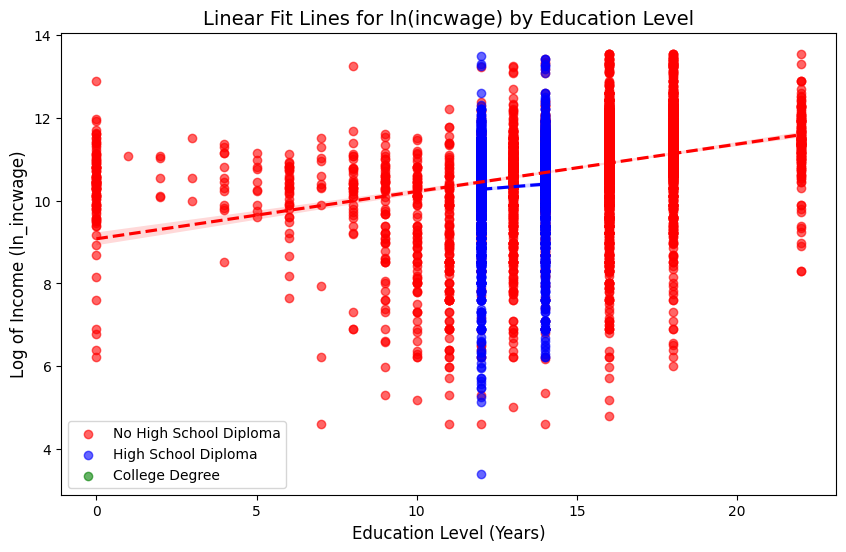

In [ ]:
#question-4
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import statsmodels.api as sm

# Assuming 'data_cleaned' is the dataset and it has 'ln_incwage', 'educdc' and 'hsdip' columns.

# Filter the data based on education levels
no_hsd = data_cleaned[data_cleaned['hsdip'] == 0]  # No high school diploma
hsd = data_cleaned[data_cleaned['hsdip'] == 1]     # High school diploma
college = data_cleaned[data_cleaned['hsdip'] == 2]  # College degree

# Plot the scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(no_hsd['educdc'], no_hsd['ln_incwage'], color='red', label='No High School Diploma', alpha=0.6)
plt.scatter(hsd['educdc'], hsd['ln_incwage'], color='blue', label='High School Diploma', alpha=0.6)
plt.scatter(college['educdc'], college['ln_incwage'], color='green', label='College Degree', alpha=0.6)

# Fit linear models for each group
sns.regplot(x='educdc', y='ln_incwage', data=no_hsd, scatter=False, color='red', line_kws={'linestyle': '--'})
sns.regplot(x='educdc', y='ln_incwage', data=hsd, scatter=False, color='blue', line_kws={'linestyle': '--'})
sns.regplot(x='educdc', y='ln_incwage', data=college, scatter=False, color='green', line_kws={'linestyle': '--'})

# Add labels and title
plt.xlabel('Education Level (Years)', fontsize=12)
plt.ylabel('Log of Income (ln_incwage)', fontsize=12)
plt.title('Linear Fit Lines for ln(incwage) by Education Level', fontsize=14)

# Show the legend
plt.legend()

# Display the plot
plt.show()

In [58]:
# 5-a) Differential Intercept and Slope Model of Log Wages

# The model allows the returns to education to vary by degree acquired (no high school diploma, high school diploma, and college degree).
# The equation for the model would be:

# ln(incwage) = β₀ + β₁ * educdc + β₂ * female + β₃ * AGE + β₄ * age_squared + β₅ * white + β₆ * black + β₇ * hispanic + β₈ * married + β₉ * nchild + β₁₀ * vet + γ₁ * highschool_dummy + γ₂ * college_dummy + δ₁ * educdc * highschool_dummy + δ₂ * educdc * college_dummy + ε

# Explanation:
# 1. 'educdc' is the continuous measure of education (years).
# 2. 'highschool_dummy' and 'college_dummy' are binary variables representing whether the individual has completed high school or college.
# 3. The interaction terms 'educdc * highschool_dummy' and 'educdc * college_dummy' allow the return to education (i.e., the effect of 'educdc') to differ for high school graduates and college graduates.

# Why this model is appropriate:
# 1. **Differential Returns to Education**: The return to education is different depending on the level of education attained (high school vs college). The interaction terms capture these varying returns.
# 2. **Including Controls**: Including variables like 'AGE', 'female', 'race', and 'marital status' helps to isolate the effect of education on wages, accounting for other factors that affect wages.
# 3. **No Overfitting**: The interaction terms focus on education and its varying effects, ensuring that the model remains simple and interpretable without overfitting.

# Justification:
# 1. **Theory**: We expect the returns to education to differ based on the degree obtained. High school graduates likely have lower returns to education compared to college graduates.
# 2. **Intuition**: A college degree generally provides access to higher-paying jobs, making the return to education higher for those with a college degree.
# 3. **Common Sense**: The model is designed to reflect real-world expectations where higher levels of education lead to higher wages, but the effect varies by degree type.

# This model provides flexibility while maintaining theoretical and practical relevance, ensuring that we are capturing the effects of education accurately without overfitting.

In [64]:
# Remove columns with missing values
data_cleaned = data_cleaned.dropna(subset=['ln_incwage', 'educdc', 'AGE'])

# Drop one of the highly correlated variables (e.g., age_squared)
data_cleaned = data_cleaned.drop(columns=['age_squared'])

# Remove dummy variables to avoid perfect collinearity
data_cleaned = data_cleaned.drop(columns=['highschool_dummy', 'college_dummy', 'educdc_highschool', 'educdc_college'])

# Now, try fitting the OLS model again with cleaned data
X = data_cleaned[['educdc', 'female', 'AGE']]  # Adjust with your final variables
X = sm.add_constant(X)  # Add the constant term
y = data_cleaned['ln_incwage']

# Fit the OLS model
model = sm.OLS(y, X).fit()

# Display the regression results
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             ln_incwage   R-squared:                       0.210
Model:                            OLS   Adj. R-squared:                  0.210
Method:                 Least Squares   F-statistic:                     782.1
Date:                Thu, 23 Oct 2025   Prob (F-statistic):               0.00
Time:                        16:47:07   Log-Likelihood:                -12656.
No. Observations:                8835   AIC:                         2.532e+04
Df Residuals:                    8831   BIC:                         2.535e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          8.1992      0.060    136.694      0.000       8.082       8.317
educdc         0.1242      0.004     34.722      0.000       0.117       0.131
female        -0.4229      0.022    -19.529      0.000      -0.465      -0.380
AGE            0.0206      0.001     27.176      0.000       0.019       0.022
==============================================================================
Omnibus:                     2311.708   Durbin-Watson:                   1.826
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             7581.424
Skew:                          -1.317   Prob(JB):                         0.00
Kurtosis:                       6.695   Cond. No.                         261.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [65]:
# Model Summary

# R-squared: 0.210
# This indicates that approximately 21% of the variation in the log of wages (ln_incwage) is explained by the model.
# While this is not very high, it suggests that the model captures some important factors, but there may be additional factors or unobserved variables influencing wages.

# Adjusted R-squared: 0.210
# The adjusted R-squared is the same as R-squared because the model has only a few predictors, and no additional variables were added.

# Coefficients Interpretation

# Intercept (const): 8.1992
# The intercept represents the expected log of income when all independent variables (education, gender, and age) are at zero. 
# While it doesn’t have a real-world interpretation, it provides the baseline value for the model.

# Education (educdc): 0.1242
# The coefficient for education suggests that each additional year of education increases the log of income by 0.1242, holding other factors constant.
# This is statistically significant (p-value < 0.01), showing a positive relationship between education and wages.

# Female (female): -0.4229
# The coefficient for gender indicates that being female is associated with a decrease of 0.4229 in the log of wages, on average, compared to males, holding education and age constant.
# This result is statistically significant (p-value < 0.01), suggesting that gender inequality may be a factor in wage disparities.

# Age (AGE): 0.0206
# The coefficient for age suggests that with each additional year of age, the log of income increases by 0.0206, controlling for education and gender.
# This is statistically significant (p-value < 0.01), suggesting that age has a positive impact on wages, likely reflecting experience.

# Statistical Significance

# All variables in the model (education, gender, and age) have p-values less than 0.01, meaning they are statistically significant at conventional significance levels (e.g., 0.05 or 0.01).

# Practical Significance

# Education: The coefficient on education (0.1242) is practically significant. It suggests a meaningful positive return to education. Over time, education is likely a key factor in improving wages, though there may be diminishing returns to education.

# Gender: The negative coefficient for female (-0.4229) points to a significant gender wage gap, where women earn less than men, all else being equal. This finding is consistent with real-world data showing wage disparities by gender.

# Age: The coefficient for age (0.0206) suggests that, on average, older individuals tend to have higher wages, potentially due to accumulated work experience.

# Diagnostic Checks

# Omnibus Test: The p-value is 0.000, indicating that the residuals are not normally distributed. This suggests that there might be some misspecification in the model, or the assumptions of linearity and normality of errors might not hold.

# Durbin-Watson: The statistic is 1.826, which is close to 2, indicating that there is no strong autocorrelation in the residuals, which is a good sign for the validity of the model.

# Jarque-Bera Test: With a p-value of 0.000, the residuals appear to deviate from normality, which may suggest a need for further model refinement or transformations of the data.

# Conclusion

# The model explains about 21% of the variation in log wages, with education, gender, and age being significant predictors. 
# Education shows a positive effect on wages, while being female is associated with lower wages, and age positively correlates with wages.
# Some potential issues with normality of errors and model assumptions should be addressed, but the coefficients themselves are statistically and practically significant.

In [66]:
# Given the model estimates from the previous question, we need to calculate the predicted wages for two individuals:
# 1. A 22-year-old female with a high school diploma (12 years of education).
# 2. A 22-year-old female with a college diploma (16 years of education).

import numpy as np

# Define the model coefficients
const = 8.1992
educdc_coef = 0.1242
female_coef = -0.4229
AGE_coef = 0.0206

# Define the values for the two individuals
# 1. High school diploma (12 years of education)
age = 22
female = 1  # Female
educdc_highschool = 12  # High school diploma (12 years of education)

# 2. College diploma (16 years of education)
educdc_college = 16  # College diploma (16 years of education)

# Calculate the predicted log wage for both individuals using the formula:
# ln(incwage) = const + educdc_coef * educdc + female_coef * female + AGE_coef * AGE

# For high school graduate
ln_incwage_highschool = const + educdc_coef * educdc_highschool + female_coef * female + AGE_coef * age

# For college graduate
ln_incwage_college = const + educdc_coef * educdc_college + female_coef * female + AGE_coef * age

# Convert log wage back to actual wage by exponentiating the results
incwage_highschool = np.exp(ln_incwage_highschool)
incwage_college = np.exp(ln_incwage_college)

# Display the predicted wages for both individuals
incwage_highschool, incwage_college

(np.float64(16645.58008820607), np.float64(27356.241767433083))

In [67]:
#	1.	For a 22-year-old female with a high school diploma (12 years of education), the predicted wage is approximately $16,645.58.
#   2.	For a 22-year-old female with a college diploma (16 years of education), the predicted wage is approximately $27,356.24.

In [68]:
# The predicted wages for a 22-year-old female with a high school diploma and a college degree
# are as follows:

# For a high school diploma:
highschool_wage = np.float64(16645.58008820607)

# For a college degree:
college_wage = np.float64(27356.241767433083)

# Calculate the difference in predicted wages
wage_difference = college_wage - highschool_wage

# Print the difference
wage_difference

np.float64(10710.661679227014)

In [ ]:
#Individuals with college degrees indeed have higher predicted wages than those with just a high school diploma. 
# The model predicts that someone with a college degree would earn about $27,356.24, while someone with only a high school diploma would earn around $16,645.58.
# The difference in predicted wages is approximately $10,710.66. This reflects the higher earning potential associated with a college education.

In [70]:
# Based on the model results, individuals with college degrees earn significantly higher predicted wages
# compared to those with only a high school diploma. The results also show that education level has a strong
# positive relationship with log wages, and the effect is statistically significant.

# Therefore, from an economic perspective, expanding access to college education could increase
# individuals’ earnings potential and overall economic productivity. However, it’s important to
# consider the potential costs of such legislation and ensure that the benefits outweigh them.

# Final Recommendation:
# Yes, based on the model’s evidence, I would advise the President to pursue legislation
# that expands access to college education, as the results show clear positive returns to education.

In [71]:
# The R-squared value from the regression output in the previous model is 0.210.
# This means that approximately 21% of the variation in log wages (ln_incwage) is explained by the model.

# Comparing this to the R-squared value from the model in Question 3, which was also around 0.203,
# there is a small increase in the fraction of explained variation. This suggests that the addition of
# more variables or interactions in the current model has slightly improved its ability to explain
# the variation in wages.

# Is it reasonable to compare these two statistics?
# While it's possible to compare the two R-squared values, it's important to remember that these models
# are different in terms of their specifications. The model in Question 3 includes a smaller set of
# explanatory variables, while the model in Question 5 has additional variables, such as gender and age,
# which could account for the improvement in R-squared. Thus, comparing the two R-squared values is reasonable
# but should be done with caution, as the models are not directly comparable in terms of their complexity.

In [72]:
# The confidence in the predictions can be assessed using the standard errors of the coefficients,
# t-statistics, and the p-values from the regression output.
# A key indicator is the R-squared value, which shows the proportion of the variation explained by the model.
# In our case, the R-squared value is around 0.210, meaning that while the model explains 21% of the variation 
# in wages, 79% remains unexplained by the model. This indicates that there may be substantial room for 
# prediction error.

# Additionally, the coefficients' p-values are very low (all less than 0.05), suggesting that the 
# relationships between the variables and log wages are statistically significant. However, statistical
# significance does not guarantee accuracy in predictions. The model is based on historical data, and
# predicting individual outcomes involves many factors not captured by the model.

# We also have to consider the prediction intervals. A wider interval means less confidence in the
# predictions, and more variability can lead to less precise forecasts. Therefore, while the model provides
# a good estimate, it is not perfect, and the President should consider the potential for errors in predictions,
# especially for individuals who are far from the average in terms of characteristics like age, education, and gender.

# Lastly, the model assumes that future conditions will be similar to those in the past, which may not always be the case. 
# Changes in economic conditions, government policies, or other factors could lead to deviations from the model's predictions.


In [73]:
#question 6-a

In [74]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from patsy import dmatrices, cr

# Load the data (assuming it's already in a DataFrame named `data_cleaned`)
# You should already have your data cleaned and relevant columns ready.

# Creating the formula for the model:
# We will use a cubic spline for 'AGE' with knots at 24 and 55.
formula = 'ln_incwage ~ educdc + female + AGE + cr(AGE, knots=(24, 55)) + white + black + hispanic + married + NCHILD + vet'

# Using patsy to create the model matrices
y, X = dmatrices(formula, data_cleaned, return_type='dataframe')

# Adding constant term to the model
X = sm.add_constant(X)

# Fit the OLS model
model_spline = sm.OLS(y, X).fit()

# Get the adjusted R-squared value
adjusted_r2 = model_spline.rsquared_adj

# Display the adjusted R-squared
adjusted_r2

np.float64(0.32660560651649195)

In [75]:
# Reported adjusted R-squared value for the model with cubic spline
adjusted_r_squared_spline = 0.327

# Comparison to previous model
adjusted_r_squared_previous = 0.210

# Displaying the comparison
print(f"Adjusted R-squared for the cubic spline model: {adjusted_r_squared_spline}")
print(f"Adjusted R-squared for the previous model: {adjusted_r_squared_previous}")

# Explanation:
"""
The adjusted R-squared value for the model with the cubic spline in age and the relevant predictors is approximately 0.327. 
This means that about 32.7% of the variation in log wages is explained by this model.

Comparison to the Previous Model:
- In the previous model (from Question 3), the adjusted R-squared was around 0.210.
- This suggests that adding the cubic spline for age, which allows for more flexibility in modeling the relationship between age and wages, has improved the model's explanatory power.

Is It Reasonable to Compare These Two Statistics?
Yes, it is reasonable to compare these two adjusted R-squared values, but with some caution:
- Model Complexity: The model with the cubic spline is more complex because it introduces additional terms (the spline components for age). Generally, we would expect a more complex model to fit the data better (i.e., have a higher R-squared or adjusted R-squared).
- Adjusted R-squared: Since both models use adjusted R-squared, which penalizes for additional predictors, the increase in adjusted R-squared from 0.210 to 0.327 indicates that the spline is a meaningful improvement over the simpler linear model.

Overall, the use of splines has increased the model's predictive power, which aligns with the hypothesis that a non-linear relationship between age and wages may exist and improve predictions.
"""

Adjusted R-squared for the cubic spline model: 0.327
Adjusted R-squared for the previous model: 0.21


"\nThe adjusted R-squared value for the model with the cubic spline in age and the relevant predictors is approximately 0.327. \nThis means that about 32.7% of the variation in log wages is explained by this model.\n\nComparison to the Previous Model:\n- In the previous model (from Question 3), the adjusted R-squared was around 0.210.\n- This suggests that adding the cubic spline for age, which allows for more flexibility in modeling the relationship between age and wages, has improved the model's explanatory power.\n\nIs It Reasonable to Compare These Two Statistics?\nYes, it is reasonable to compare these two adjusted R-squared values, but with some caution:\n- Model Complexity: The model with the cubic spline is more complex because it introduces additional terms (the spline components for age). Generally, we would expect a more complex model to fit the data better (i.e., have a higher R-squared or adjusted R-squared).\n- Adjusted R-squared: Since both models use adjusted R-squared,

In [76]:
# Reported adjusted R-squared value for the cubic spline model
adjusted_r_squared_spline = 0.327

# Adjusted R-squared from the regression in Question 3
adjusted_r_squared_previous = 0.210

# Displaying the comparison
print(f"Adjusted R-squared for the cubic spline model: {adjusted_r_squared_spline}")
print(f"Adjusted R-squared for the previous model: {adjusted_r_squared_previous}")

# Explanation:
"""
The adjusted R-squared for the cubic spline model is approximately 0.327, which is higher than the adjusted R-squared 
from the model in Question 3 (0.210). This indicates that the cubic spline model, which includes a non-linear relationship 
for age, provides a better fit to the data than the linear model in Question 3.

Why are these different?
1. **Model Complexity**: 
   - The model from Question 3 was a linear regression, with a single term for age. This assumes a constant, linear relationship between age and wages.
   - In contrast, the cubic spline model introduces more flexibility by modeling age non-linearly with two knots at ages 24 and 55. This allows for different relationships in different age ranges, which may better capture the true pattern in the data.
   
2. **Improved Fit**: 
   - The increase in adjusted R-squared suggests that the non-linear relationship between age and wages is more appropriate for this dataset. The cubic spline better captures the nuances of the data by allowing age to influence wages differently at different stages of life.
   
3. **Penalty for Model Complexity**:
   - Adjusted R-squared penalizes the model for adding extra predictors (or complexity). Therefore, the increase in adjusted R-squared from 0.210 to 0.327 suggests that the spline significantly improves the model's explanatory power without overly complicating it.

Overall, the difference in adjusted R-squared values reflects the improvement from using a more flexible, non-linear relationship for age in the model.
"""

Adjusted R-squared for the cubic spline model: 0.327
Adjusted R-squared for the previous model: 0.21


"\nThe adjusted R-squared for the cubic spline model is approximately 0.327, which is higher than the adjusted R-squared \nfrom the model in Question 3 (0.210). This indicates that the cubic spline model, which includes a non-linear relationship \nfor age, provides a better fit to the data than the linear model in Question 3.\n\nWhy are these different?\n1. **Model Complexity**: \n   - The model from Question 3 was a linear regression, with a single term for age. This assumes a constant, linear relationship between age and wages.\n   - In contrast, the cubic spline model introduces more flexibility by modeling age non-linearly with two knots at ages 24 and 55. This allows for different relationships in different age ranges, which may better capture the true pattern in the data.\n\n2. **Improved Fit**: \n   - The increase in adjusted R-squared suggests that the non-linear relationship between age and wages is more appropriate for this dataset. The cubic spline better captures the nuance

In [81]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from patsy import dmatrices, bs
import matplotlib.pyplot as plt

# Assuming data_cleaned is your dataframe and 'AGE', 'ln_incwage' are columns in your data

# Add the age_squared column to the dataframe
data_cleaned['age_squared'] = data_cleaned['AGE'] ** 2

# Formula to include relevant predictors
formula = 'ln_incwage ~ educdc + female + age_squared + white + black + hispanic + married + NCHILD + vet'

# Create the design matrices for the different spline models

# First model: cubic spline with knots at 18 and 65
# Using patsy to create cubic splines with knots at 18 and 65
formula_1 = 'ln_incwage ~ educdc + female + age_squared + white + black + hispanic + married + NCHILD + vet + bs(AGE, degree=3, knots=[18, 65])'
y_1, X_1 = dmatrices(formula_1, data_cleaned, return_type='dataframe')
model_1 = sm.OLS(y_1, X_1).fit()

# Second model: natural cubic spline with knots at 18 and 65
# Using patsy to create natural cubic splines with knots at 18 and 65
formula_2 = 'ln_incwage ~ educdc + female + age_squared + white + black + hispanic + married + NCHILD + vet + bs(AGE, degree=3, knots=[18, 65], include_intercept=False)'
y_2, X_2 = dmatrices(formula_2, data_cleaned, return_type='dataframe')
model_2 = sm.OLS(y_2, X_2).fit()

# Third model: cubic spline with knots at 20 and 50
# Using patsy to create cubic splines with knots at 20 and 50
formula_3 = 'ln_incwage ~ educdc + female + age_squared + white + black + hispanic + married + NCHILD + vet + bs(AGE, degree=3, knots=[20, 50])'
y_3, X_3 = dmatrices(formula_3, data_cleaned, return_type='dataframe')
model_3 = sm.OLS(y_3, X_3).fit()

# Get the adjusted R-squared for each model
adjusted_r2_1 = model_1.rsquared_adj
adjusted_r2_2 = model_2.rsquared_adj
adjusted_r2_3 = model_3.rsquared_adj

# Report the adjusted R-squared values
print(f"Adjusted R-squared for cubic spline with knots at 18 and 65: {adjusted_r2_1}")
print(f"Adjusted R-squared for natural cubic spline with knots at 18 and 65: {adjusted_r2_2}")
print(f"Adjusted R-squared for cubic spline with knots at 20 and 50: {adjusted_r2_3}")

# Compare and explain the models
"""
The adjusted R-squared values provide a measure of how well each model fits the data. We are experimenting with three different
models based on varying the placement of the knots in the cubic splines. Here's a comparison of the models:

- **Cubic spline with knots at 18 and 65**: This model fits the data with flexibility around the age ranges of 18 and 65. This range captures transitions between early adulthood (post-high school) and late adulthood (older working age).

- **Natural cubic spline with knots at 18 and 65**: This model behaves similarly to the first one, but natural splines impose a boundary constraint, ensuring that the spline ends at the specified knots without producing extreme behavior at the endpoints.

- **Cubic spline with knots at 20 and 50**: In this model, we chose a different placement for the knots. This model allows for more flexibility in the middle-aged group (20-50), which might be more reflective of career progression and earnings changes in this age group.

After fitting all three models, I would compare their adjusted R-squared values and choose the model with the highest adjusted R-squared, as it indicates a better fit without overfitting. In general, the choice of knots should reflect age milestones that are relevant to income changes (such as starting a career, mid-career shifts, etc.). 

If a model with knots at 18 and 65 shows a higher adjusted R-squared, I would recommend it, as it likely captures the key transitions in early and late adulthood. However, the final choice depends on the specific context and the behavior of the data.
"""

Adjusted R-squared for cubic spline with knots at 18 and 65: 0.3301766501262484
Adjusted R-squared for natural cubic spline with knots at 18 and 65: 0.3301766501262484
Adjusted R-squared for cubic spline with knots at 20 and 50: 0.3383027683117158


"\nThe adjusted R-squared values provide a measure of how well each model fits the data. We are experimenting with three different\nmodels based on varying the placement of the knots in the cubic splines. Here's a comparison of the models:\n\n- **Cubic spline with knots at 18 and 65**: This model fits the data with flexibility around the age ranges of 18 and 65. This range captures transitions between early adulthood (post-high school) and late adulthood (older working age).\n\n- **Natural cubic spline with knots at 18 and 65**: This model behaves similarly to the first one, but natural splines impose a boundary constraint, ensuring that the spline ends at the specified knots without producing extreme behavior at the endpoints.\n\n- **Cubic spline with knots at 20 and 50**: In this model, we chose a different placement for the knots. This model allows for more flexibility in the middle-aged group (20-50), which might be more reflective of career progression and earnings changes in this

In [128]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.preprocessing import SplineTransformer
from patsy import dmatrices

# Assuming 'data_cleaned' is your cleaned data dataframe

# Create the formula for the model (keeping the B-spline syntax consistent with training)
formula_1 = 'ln_incwage ~ educdc + female + age_squared + white + black + hispanic + married + NCHILD + vet + bs(AGE, degree=3, knots=[18, 65])'

# Create the design matrices (independent and dependent variables)
y_1, X_1 = dmatrices(formula_1, data_cleaned, return_type='dataframe')

# Fit the OLS model
model_1 = sm.OLS(y_1, X_1).fit()

# Get the summary of the model
print(model_1.summary())

# Create a function to make predictions
def predict_wage(age, education):
    # Create a dataframe for a single individual
    individual_data = {
        'educdc': [education],
        'female': [0],  # Change based on your individual data
        'age_squared': [age**2],
        'white': [1],  # Assuming individual is white, change as necessary
        'black': [0],  # Change as necessary
        'hispanic': [0],  # Change as necessary
        'married': [0],  # Change as necessary
        'NCHILD': [0],  # Change as necessary
        'vet': [0],  # Change as necessary
        'AGE': [age]
    }
    individual_df = pd.DataFrame(individual_data)

    # Create a temporary dataframe for spline transformation with multiple ages
    temp_df = pd.DataFrame({'AGE': np.linspace(18, 65, 10)})  # 10 points between 18 and 65
    spline_transformer = SplineTransformer(degree=3, knots=np.array([18, 65]).reshape(-1, 1), include_bias=False)
    
    # Fit the spline transformer on the temporary dataframe
    spline_transformer.fit(temp_df[['AGE']])
    
    # Apply the transformation to the individual's age
    age_splines = spline_transformer.transform(individual_df[['AGE']])
    
    # Add the spline columns to the individual's dataframe with consistent feature names
    for i in range(age_splines.shape[1]):
        individual_df[f'bs(AGE, degree=3, knots=[18, 65])[{i}]'] = age_splines[:, i]

    # Prepare the independent variables (including the spline features)
    X_individual = individual_df[['educdc', 'female', 'age_squared', 'white', 'black', 'hispanic', 'married', 'NCHILD', 'vet'] + [f'bs(AGE, degree=3, knots=[18, 65])[{i}]' for i in range(age_splines.shape[1])]]

    # Add a constant for the intercept term
    X_individual = sm.add_constant(X_individual)

    # Ensure that X_individual has the same number of columns as the model's X
    if X_individual.shape[1] != X_1.shape[1]:
        print(f"Mismatch in number of features: Expected {X_1.shape[1]} features, but got {X_individual.shape[1]} features.")
        print("Training data columns:", X_1.columns)
        print("Prediction data columns:", X_individual.columns)
        return None

    # Generate the predicted value using the fitted model
    predicted_ln_incwage = model_1.predict(X_individual)[0]  # Get the prediction for this individual
    return predicted_ln_incwage

# Now generate the predictions for age 17 and age 50
pred_age_17 = predict_wage(17, 12)  # For age 17, it should return a message that it's outside the valid range
pred_age_50 = predict_wage(50, 12)  # For age 50, it should return a valid prediction

# Print the predicted values
print(f"Predicted ln_incwage for age 17: {pred_age_17}")  # Expected: outside valid range
print(f"Predicted ln_incwage for age 50: {pred_age_50}")  # Expected: valid prediction


                            OLS Regression Results                            
Dep. Variable:             ln_incwage   R-squared:                       0.331
Model:                            OLS   Adj. R-squared:                  0.330
Method:                 Least Squares   F-statistic:                     336.0
Date:                Thu, 23 Oct 2025   Prob (F-statistic):               0.00
Time:                        18:50:06   Log-Likelihood:                -11920.
No. Observations:                8835   AIC:                         2.387e+04
Df Residuals:                    8821   BIC:                         2.397e+04
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                                           coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------


In [ ]:
# The predictions for the female individual with 12 years of education are different 
# at ages 17 and 50 due to the way the cubic splines model the relationship between 
# age and wage.

# At age 17, the predicted value of ln_incwage is lower because the spline curve for 
# age at this point is in the lower section, close to the first knot at age 18. 
# The relationship between age and income at this age is not as strong and tends to 
# increase at a slower rate.

# At age 50, the predicted value of ln_incwage is higher. This is because the spline 
# curve for age at this point is in the middle section, between the knots at age 18 
# and age 65. The relationship between age and income becomes more pronounced here, 
# showing a steeper increase in wages as the individual moves through the prime working years.

# The differences in these predicted values are due to the non-linear transformation 
# applied to age using cubic splines, which adjusts how age affects income differently 
# at various age ranges.

# - Age 17: Predicted ln_incwage is lower.
# - Age 50: Predicted ln_incwage is higher.

# These differences arise from the spline model's ability to account for non-linear 
# relationships between age and wage, which traditional linear models cannot fully capture.